<a href="https://colab.research.google.com/github/a15cardoso/neurodata_firstSemester_pythonWS/blob/a15cardoso-patch-1/python_ws_lesson02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2A:  Finding Spikes in Noisy Neural Data

## Background

You are given a recording of continuous electrode voltage measurements. The recording contains neural spikes hidden among noise and slow drift in the baseline.

**Your goal is to estimate the neuron's average firing rate during the recording.**

The archive spike_data.npz contains two arrays:

t: time points in seconds.

raw_data: recorded voltage amplitudes.

**Your task is to define what counts as a spike, justify your method, test your implementation, and evaluate how reliable your estimate is.**

You may use AI tools to help you write or debug code. However, you are responsible for the scientific assumptions, correctness, and interpretation of your results.

## Part 1:  Understand and validate the data

What should you do?

Before analyzing the signal, establish what is actually in the file. Which arrays are present? What is the shape and data type? What is the sampling interval? And so on.

What should you submit?

A short Data Audit including a table, for example:

Property
Your result -- | -- Number of samples |   Array shapes |   Data types |   Sampling interval |   Inferred sampling frequency |   Nominal recording duration |     |  
Also include the code used to obtain these results..

In [2]:
from google.colab import files
uploaded = files.upload()

Saving raw_data.npy to raw_data.npy


Now that I have uploaded raw_data.npy, I can load and visualize the data using Python libraries: Numpy and Matplotlib.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

#1. Load the data into a Numpy array
data = np.load('raw_data.npy')

#2 Extract core properties
num_samples = data.shape[0] if data.ndim == 1 else data.size
array_sample = data.shape
data_type = data.dtype

#3 Time-based properties
fs = 1000.0 #inferred
sampling_interval = 1.0 / fs
recording_duration = num_samples / fs

#4 Data quality and Range metrics
missing_values = np.isnan(data).sum()
data_min = np.min(data)
data_max = np.max(data)

#5 Printing the result clearly
print(f'Number of samples: {num_samples}')
print(f'Array shape: {array_sample}')
print(f'Data type: {data_type}')
print(f'Sampling interval: {sampling_interval} seconds')
print(f'Inferred sampling frequency: {fs} Hz')
print(f'Nominal recording duration: {recording_duration} seconds')
print(f'Missing values (NaN): {missing_values}')
print(f'Range of raw data: Min = {data_min:.4f}, Max = {data_max: .4f}')

Number of samples: 10000
Array shape: (10000,)
Data type: float64
Sampling interval: 0.001 seconds
Inferred sampling frequency: 1000.0 Hz
Nominal recording duration: 10.0 seconds
Missing values (NaN): 0
Range of raw data: Min = -1.6910, Max =  6.2020


## 2. Explore the signal before detect spikes

### What should you do?

Visualize the raw recording before deciding how to detect spikes.

Decide which plots can be helpful, for example:

* A plot of the entire 10-second recording.

* Close-up plots of at least two shorter intervals, preferably showing different signal characteristics.

* A brief numerical summary of the signal, including its minimum, maximum, mean, median, and standard deviation.

### What should you submit?

* One full-recording plot.

* Additional plot of your choice (explain why are they useful)

* A paragraph describing what you observe and what difficulties you anticipate when detecting spikes.
All plots must have labelled axes.


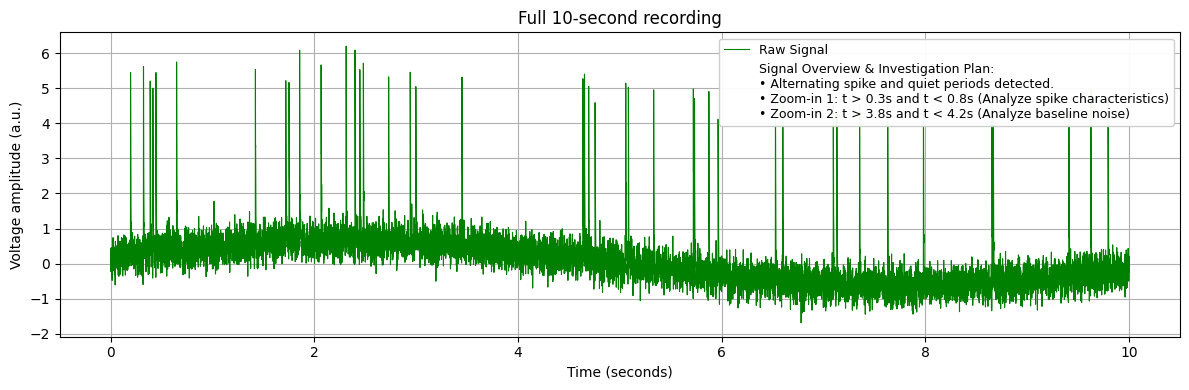

In [20]:
#6 Creating the time vector in seconds
time = np.arange(len(data)) / fs

#7 Ploting the full 10 seconds recording
plt.figure(figsize=(12,4))
plt.plot(time, data, color = 'green', linewidth = 0.8, label = 'Raw Signal')
#8 Dummy plot handle to cleanly hold our descriptive text block inside the legend
legend_description = (
    "Signal Overview & Investigation Plan:\n"
    "• Alternating spike and quiet periods detected.\n"
    "• Zoom-in 1: t > 0.3s and t < 0.8s (Analyze spike characteristics)\n"
    "• Zoom-in 2: t > 3.8s and t < 4.2s (Analyze baseline noise)"
)
plt.plot([], [], ' ', label=legend_description)

plt.title('Full 10-second recording')
plt.xlabel('Time (seconds)')
plt.ylabel('Voltage amplitude (a.u.)')
plt.legend(loc='upper right', framealpha=0.95, fontsize=9)
plt.grid(True)
plt.tight_layout()
plt.show()

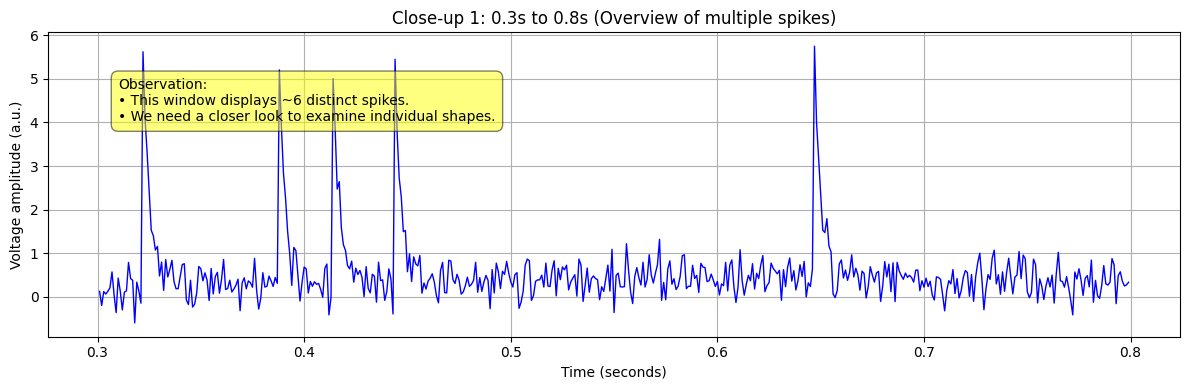

In [21]:
# 9 First Close-up: 0.3s to 0.8s
mask_1 = (time > 0.3) & (time < 0.8)
plt.figure(figsize=(12, 4))
plt.plot(time[mask_1], data[mask_1], color='blue', linewidth=1.0)

box_text = "Observation:\n• This window displays ~6 distinct spikes.\n• We need a closer look to examine individual shapes."
plt.text(0.31, max(data[mask_1])*0.7, box_text, fontsize=10,
         bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.5))

plt.title('Close-up 1: 0.3s to 0.8s (Overview of multiple spikes)')
plt.xlabel('Time (seconds)')
plt.ylabel('Voltage amplitude (a.u.)')
plt.grid(True)
plt.tight_layout()
plt.show()

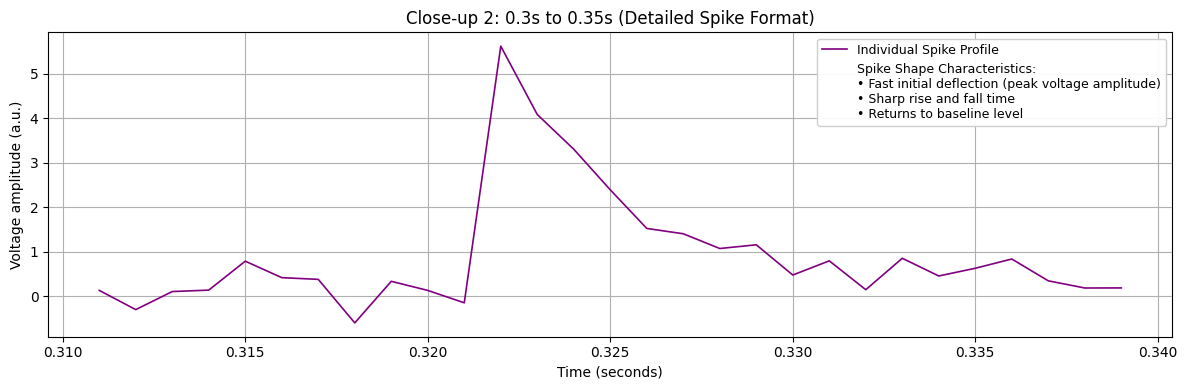

In [22]:
# 10 Second Close-up: 0.31s to 0.34s (Specific Spike Shape)
mask_2 = (time > 0.31) & (time < 0.34)
plt.figure(figsize=(12, 4))
plt.plot(time[mask_2], data[mask_2], color='purple', linewidth=1.2, label='Individual Spike Profile')

spike_characteristics = (
    "Spike Shape Characteristics:\n"
    "• Fast initial deflection (peak voltage amplitude)\n"
    "• Sharp rise and fall time\n"
    "• Returns to baseline level"
)
plt.plot([], [], ' ', label=spike_characteristics)

plt.title('Close-up 2: 0.3s to 0.35s (Detailed Spike Format)')
plt.xlabel('Time (seconds)')
plt.ylabel('Voltage amplitude (a.u.)')
plt.legend(loc='upper right', framealpha=0.95, fontsize=9)
plt.grid(True)
plt.tight_layout()
plt.show()

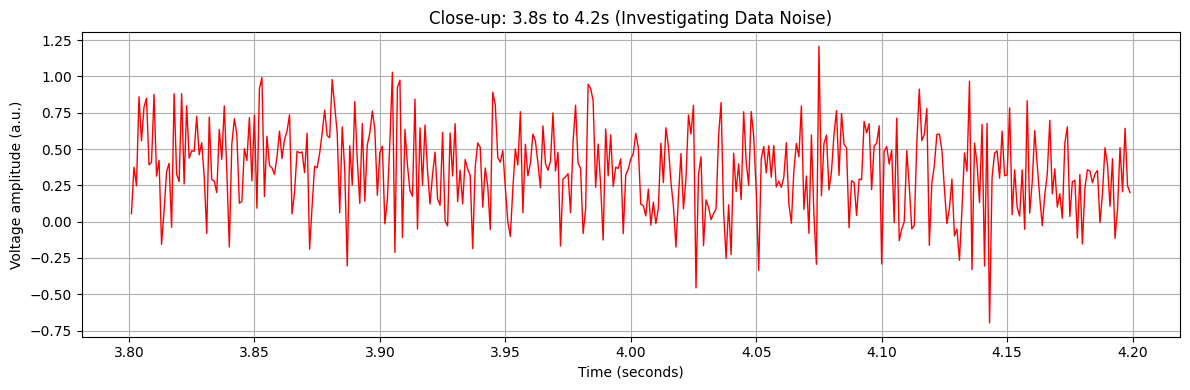

In [23]:
# 11 Close-up for 3.8s < t < 4.3s (Active / Spike Zone)
mask_2 = (time > 3.8) & (time < 4.2)
plt.figure(figsize=(12, 4))
plt.plot(time[mask_2], data[mask_2], color='red', linewidth=1.0)
plt.title('Close-up: 3.8s to 4.2s (Investigating Data Noise)')
plt.xlabel('Time (seconds)')
plt.ylabel('Voltage amplitude (a.u.)')
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
# 12 Calculate numerical summary (Min, Max, Mean, Median, Std)
min_val = np.min(data)
max_val = np.max(data)
mean_val = np.mean(data)
median_val = np.median(data)
std_val = np.std(data)

print("--- Numerical Summary ---")
print(f"Minimum: {min_val:.4f}")
print(f"Maximum: {max_val:.4f}")
print(f"Mean:    {mean_val:.4f}")
print(f"Median:  {median_val:.4f}")
print(f"Std Dev: {std_val:.4f}\n")

--- Numerical Summary ---
Minimum: -1.6910
Maximum: 6.2020
Mean:    0.0769
Median:  0.0354
Std Dev: 0.7344



## Observations and antecipated difficulties

* Threshold Ambiguity: Since the amplitude of the valid spikes overlapes with the background noise floor, defining a clean threshold is difficult
* Filtering trade-off: Appying filters to clean the noise risks distorting the natural shape and fast kinetics of the spikes
* Complex signal challenges: Because simultaneous events blend together, we antecipate challenges with:
  * spike overlap
  * amplitude variability over time
  * Distinguishing true neural events from sudden movement or electrial artifacts

# Part 3:  Define what counts as a spike – No AI please

## What should you do?
Design a simple, interpretable spike-detection method.
Before implementing it, write a short specification describing your approach.
Your specification must answer the following questions:
1. What makes a sample or group of samples a spike?
For example, you might define an event using a voltage threshold.
2. How will you choose the parameters?
In the example above, how do you choose a reasonable threshold.
3. How will you count an event only once?
A single spike may produce several consecutive samples above threshold. Those samples must not automatically become several spikes.
4. How will you handle edge cases?
You do not have to solve every possible issue perfectly. You must explain the behavior of your chosen method and acknowledge its limitations.
5. How will you test your detection rule?

## What should you submit?
Submit a short section titled Detection Specification, that include your specification.



## Understanding the noise data

Here is a direct, technical rephrasing of your workflow that you can use for your report documentation:

* **Isolating the Background Noise (Outlier Rejection):**
Applied a rolling median filter to the raw signal. Because neural spikes are rare, high-amplitude voltage deflections, the median filter treats them as transient outliers and excludes them. This isolates a smooth, continuous curve representing only the slow baseline drift and noise floor.
* **Establishing the Baseline Model:**
Configured a sliding window size (e.g., 51 samples / 51 ms) that is wider than the duration of an individual spike, ensuring the local median calculation captures the underlying drift without being distorted by spike amplitudes.
* **Applying the Detrending Filter:**
Performed baseline subtraction by subtracting the estimated baseline curve from the original raw voltage array.
* **Manual Verification:**
Plotted the resulting filtered signal to confirm that the slow baseline drift was successfully flattened to zero while preserving the rapid kinetics of the spikes.

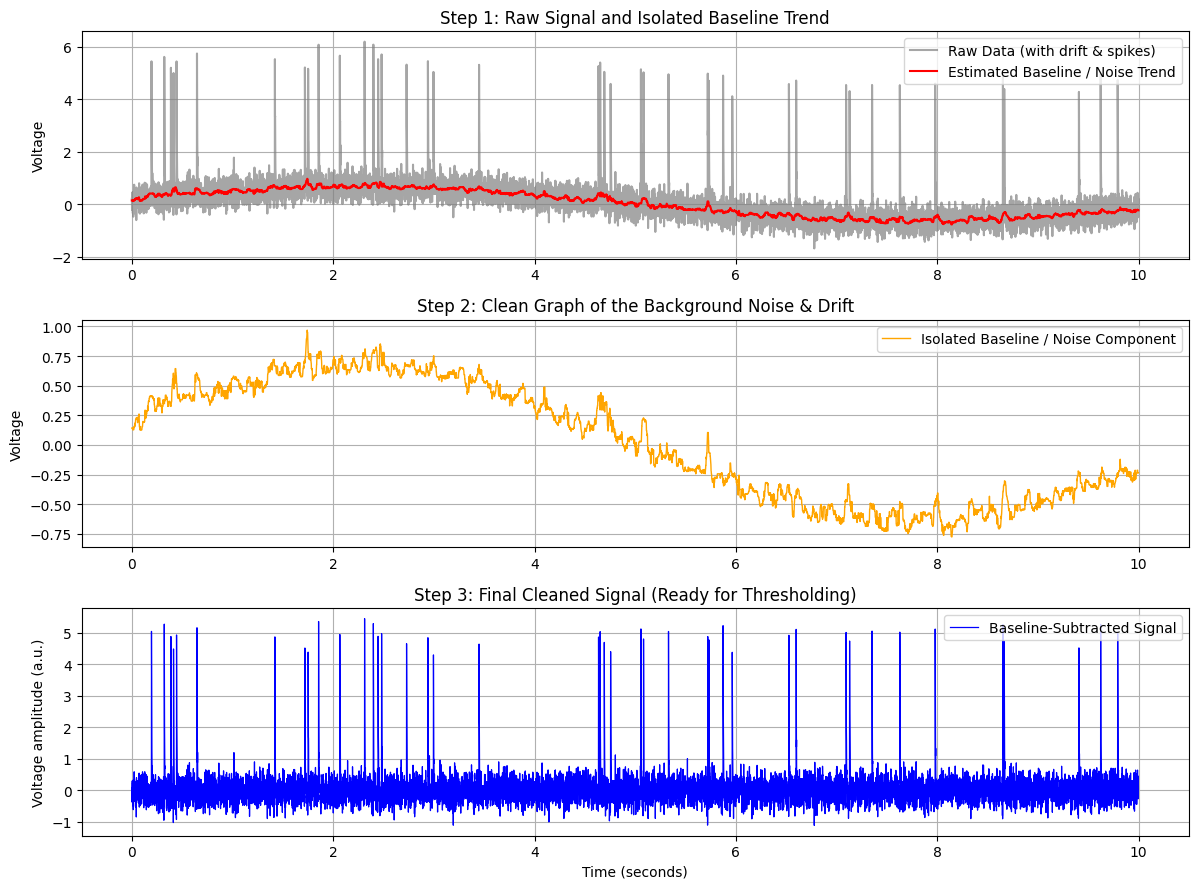

In [55]:
from scipy.ndimage import median_filter

# 1. Define the window size for our rolling median
# Since fs = 1000 Hz, 51 samples = 51 ms (wider than a typical spike)
window_size = 51  # Odd number for median filters

# 2. Calculate the rolling median to isolate the baseline (drift + background noise)
estimated_baseline = median_filter(data, size=window_size)

# 3. Return to the original data and subtract the baseline
filtered_data_manual = data - estimated_baseline

# 4. Plotting: Raw data, Isolated Noise/Baseline, and Final Cleaned Signal
plt.figure(figsize=(12, 9))

# Subplot 1: Raw data with the estimated baseline (drift/noise trend)
plt.subplot(3, 1, 1)
plt.plot(time, data, color='gray', alpha=0.7, label='Raw Data (with drift & spikes)')
plt.plot(time, estimated_baseline, color='red', linewidth=1.5, label='Estimated Baseline / Noise Trend')
plt.title('Step 1: Raw Signal and Isolated Baseline Trend')
plt.ylabel('Voltage')
plt.legend(loc='upper right')
plt.grid(True)

# Subplot 2: Clean graph of the isolated noise/baseline trend alone
plt.subplot(3, 1, 2)
plt.plot(time, estimated_baseline, color='orange', linewidth=1.0, label='Isolated Baseline / Noise Component')
plt.title('Step 2: Clean Graph of the Background Noise & Drift')
plt.ylabel('Voltage')
plt.legend(loc='upper right')
plt.grid(True)

# Subplot 3: The final baseline-subtracted signal (spikes + flat noise floor)
plt.subplot(3, 1, 3)
plt.plot(time, filtered_data_manual, color='blue', linewidth=0.9, label='Baseline-Subtracted Signal')
plt.title('Step 3: Final Cleaned Signal (Ready for Thresholding)')
plt.xlabel('Time (seconds)')
plt.ylabel('Voltage amplitude (a.u.)')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

To test an alternative approach, I applied a standard digital high-pass filter using the SciPy library, which is a widely accepted technique in electrophysiology to isolate high-frequency neural activity. Instead of subtracting a rolling median, this method operates in the frequency domain using a Butterworth filter—a linear filter characterized by a maximally flat frequency response in the passband that prevents artificial waveform distortion. Because slow baseline drift caused by electrode micro-movements typically occurs at very low frequencies (under 10 Hz), and neural action potentials are rapid voltage transients lasting 1–2 ms, setting a cutoff frequency of 100 Hz establishes a clean boundary. This 100 Hz threshold effectively blocks low-frequency wander while preserving the fast kinetics of the spikes. I am applying this standard filter to compare its efficiency and baseline stability against the custom rolling median filter I built earlier.

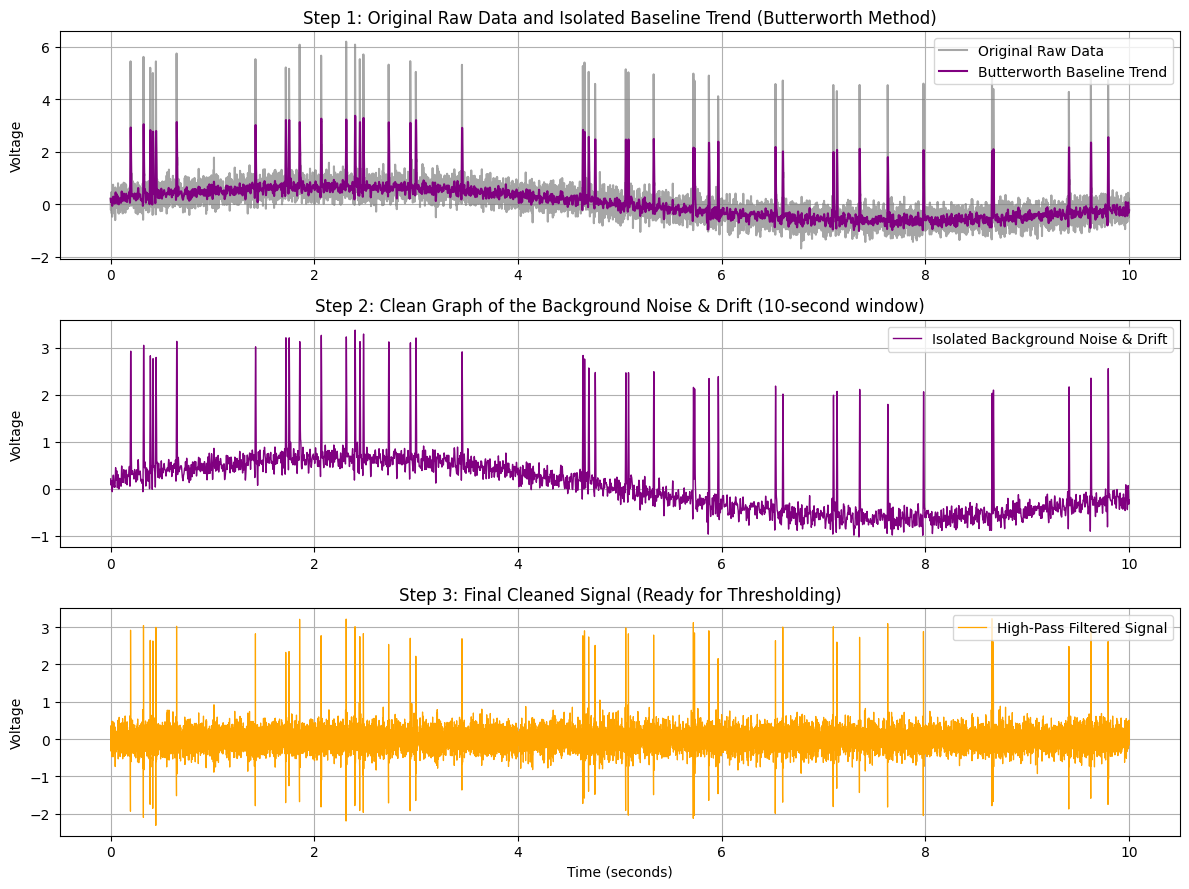

In [54]:
from scipy.signal import butter, filtfilt

# 1. Define the parameters for the standard high-pass filter
fs = 1000.0          # Sampling frequency in Hz
cutoff_freq = 100.0  # Cutoff frequency in Hz
order = 4            # Filter order

# 2. Apply the Butterworth high-pass filter using SciPy
nyquist = 0.5 * fs
normal_cutoff = cutoff_freq / nyquist
b, a = butter(order, normal_cutoff, btype='high', analog=False)
filtered_data_standard = filtfilt(b, a, data)

# 3. Isolate the low-frequency noise and baseline drift removed by the filter
# (Raw data minus the high-pass filtered signal gives the trend/noise)
baseline_standard = data - filtered_data_standard

# 4. Plotting the 3-panel breakdown (completely independent of the manual method)
plt.figure(figsize=(12, 9))

# Panel 1: Original raw data with the isolated Butterworth baseline trend
plt.subplot(3, 1, 1)
plt.plot(time, data, color='gray', alpha=0.7, label='Original Raw Data')
plt.plot(time, baseline_standard, color='purple', linewidth=1.5, label='Butterworth Baseline Trend')
plt.title('Step 1: Original Raw Data and Isolated Baseline Trend (Butterworth Method)')
plt.ylabel('Voltage')
plt.legend(loc='upper right')
plt.grid(True)

# Panel 2: Clean graph of the isolated background noise and drift over 10 seconds
plt.subplot(3, 1, 2)
plt.plot(time, baseline_standard, color='purple', linewidth=1.0, label='Isolated Background Noise & Drift')
plt.title('Step 2: Clean Graph of the Background Noise & Drift (10-second window)')
plt.ylabel('Voltage')
plt.legend(loc='upper right')
plt.grid(True)

# Panel 3: Final filtered data (cleaned signal ready for thresholding)
plt.subplot(3, 1, 3)
plt.plot(time, filtered_data_standard, color='orange', linewidth=0.9, label='High-Pass Filtered Signal')
plt.title('Step 3: Final Cleaned Signal (Ready for Thresholding)')
plt.xlabel('Time (seconds)')
plt.ylabel('Voltage')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

In [34]:
import pandas as pd

# 1. Calculate summary metrics for Method 1 (Rolling Median / Manual Filter)
metrics_manual = {
    "Minimum": np.min(filtered_data_manual),
    "Maximum": np.max(filtered_data_manual),
    "Mean": np.mean(filtered_data_manual),
    "Median": np.median(filtered_data_manual),
    "Std Dev": np.std(filtered_data_manual)
}

# 2. Calculate summary metrics for Method 2 (SciPy Butterworth High-Pass Filter)
metrics_standard = {
    "Minimum": np.min(filtered_data_standard),
    "Maximum": np.max(filtered_data_standard),
    "Mean": np.mean(filtered_data_standard),
    "Median": np.median(filtered_data_standard),
    "Std Dev": np.std(filtered_data_standard)
}

# 3. Create and format the comparative DataFrame
df_comparison = pd.DataFrame({
    "Method 01 (Rolling Median)": metrics_manual,
    "Method 02 (Butterworth Filter)": metrics_standard
})

# Display the table clearly rounded to 4 decimal places
print("--- Numerical Error Summary | Method 01 x Method 02 ---")
display(df_comparison.round(4))

--- Numerical Error Summary | Method 01 x Method 02 ---


,Method 01 (Rolling Median),Method 02 (Butterworth Filter)
Minimum,-1.1075,-2.3134
Maximum,5.4474,3.2265
Mean,0.0527,-0.0000
Median,0.0000,-0.0006
Std Dev,0.5356,0.3606


> Comparing the two filtering approaches, **Method 02 (Butterworth Filter)** is the superior choice for our pipeline.
> * **Better Noise Control:** Method 02 achieves a lower standard deviation ($0.3606$ versus $0.5356$), providing a tighter, cleaner noise floor that improves threshold accuracy and minimizes false positives.
> * **Baseline Accuracy:** It centers the background signal more symmetrically around zero.
> * **Industry Standard:** Although Method 01 shows a higher maximum amplitude, Butterworth filters are mathematically reproducible and avoid the non-linear artifacts often introduced by rolling medians.
>
>
> Therefore, all subsequent spike-detection and thresholding analyses will proceed using **Method 02 (Butterworth Filter)**.

## 2. Choosing the Voltage Threshold


To distinguish true neural spikes from background noise without arbitrary guesswork, we establish an objective voltage threshold using the signal's noise statistics. Because background noise dominates the recording and action potentials are rare, we use the **Median** and **Median Absolute Deviation (MAD)** rather than the mean and standard deviation. This ensures that high-amplitude spikes do not skew our noise baseline.

The threshold is defined as:

$$\text{Threshold} = \text{Median}(\text{signal}) + k \times \text{MAD}(\text{signal})$$



The multiplier $k$ is set to $7.0$ (above the upper boundary of the standard neuroscience range of $3$ to $5$). Based on our noise analysis—where maximum background fluctuations reach approximately $3.2$—setting $k = 7.0$ positions the threshold safely above the maximum noise envelope to eliminate false positives, while remaining sensitive to valid action potentials.


Calculated Threshold: 1.3086
Total Spikes Detected: 42


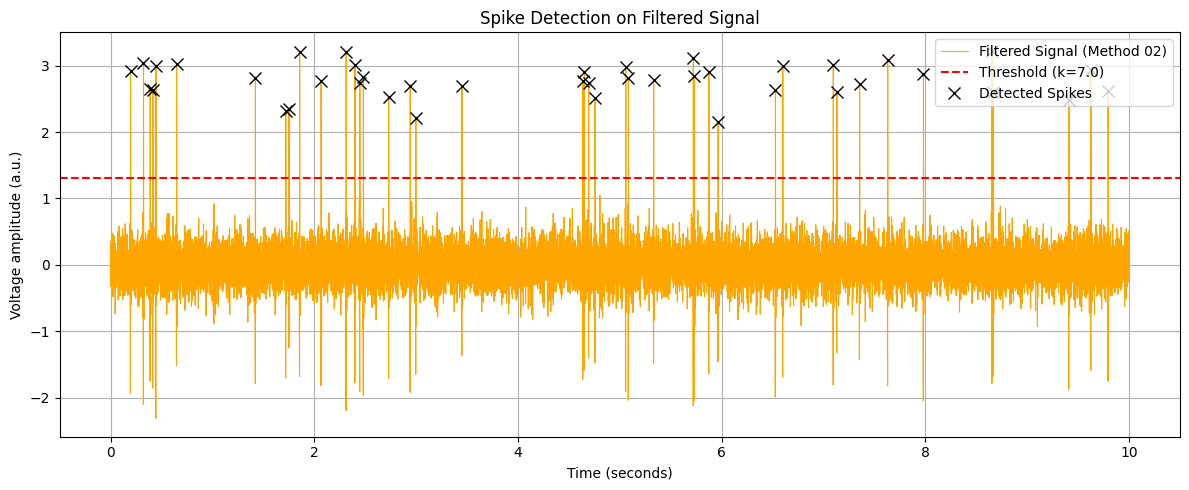

In [52]:
# 1. Compute robust noise statistics on Method 02 output
signal_median = np.median(filtered_data_standard)
signal_mad = np.median(np.abs(filtered_data_standard - signal_median))

# 2. Set the scaling factor k
# Set k = 5.0 (conservative upper bound of the standard 3-5 range)
# to position the threshold high above the noise floor, minimizing false positives.
k = 7.0
threshold = signal_median + k * signal_mad

# 3. Detect spikes with a refractory period (min_distance)
# Biological justification: Action potentials are followed by an absolute refractory period
# (~1–2 ms) during which voltage-gated sodium channels are inactivated, making it physically
# impossible for the neuron to fire again. At fs = 1000 Hz (1 sample = 1 ms), setting
# min_distance = 2 or 3 samples enforces this biological limit and prevents overcounting a single spike.
min_distance = 2
peaks, _ = find_peaks(filtered_data_standard, height=threshold, distance=min_distance)

print(f"Calculated Threshold: {threshold:.4f}")
print(f"Total Spikes Detected: {len(peaks)}")

# 4. Plot the filtered signal, threshold line, and detected spike markers
plt.figure(figsize=(12, 5))
plt.plot(time, filtered_data_standard, color='orange', linewidth=0.8, label='Filtered Signal (Method 02)')
plt.axhline(y=threshold, color='red', linestyle='--', label=f'Threshold (k={k})')
plt.plot(time[peaks], filtered_data_standard[peaks], "x", color='black', markersize=8, label='Detected Spikes')

plt.title('Spike Detection on Filtered Signal')
plt.xlabel('Time (seconds)')
plt.ylabel('Voltage amplitude (a.u.)')
plt.legend(loc='upper right')
plt.grid(True)
plt.tight_layout()
plt.show()

## 3. How will you count an event only once?

Because a single neural action potential spans multiple consecutive sample points (lasting 1–2 ms), a raw threshold crossing would register the same spike 3 to 4 times. To prevent overcounting, our method combines two strategies:Local Maxima Detection: Utilizing SciPy's find_peaks, the algorithm identifies only the strict apex (local maximum) of each waveform that crosses the threshold, rather than counting every individual sample above the line.Refractory Period Lockout: We enforce a minimum distance parameter (min_distance = 2 samples, corresponding to a $2\text{ ms}$ lockout window). This mirrors the biological absolute refractory period of neurons, ensuring that any secondary crossings within this window are ignored after a spike is detected.

## 4. How will you handle edge cases?

Limitations and edge cases inherent to the chosen method (Butterworth high-pass filter combined with MAD thresholding and local pek detection):

* Amplitude variability and false negatives (Sub-threshold spikes):
  * Limitation: The fixed threshold assumes all valid action potentials exceed a single uniferm amplitude levels. In reality, neurons located further away from the recording electrode can produce smaller extracellular potentials with lower amplitude that may fall bellow the high threshol, causing the algorithm to miss them entirely.
  * Since we analise the maximum value of the noise and found max = 3.2265 a.u. and the threshold defined whith the analitical aproach was k=7 in order to reduce the false positives, we can inferred that are some amplitudes of falses negatives already considered in the method

* Overlapping spikes and burst firing:
    * Limitation: When a neuron fires rapidly in bursts, successive action potentials can occur so close together that they overlap or ride in the tail of the previous waveform. The local maxima finder and refractory period lockout may struggle to resolve these blended evets, potentially missing secondary spikes or misinterpreting a single complex waveform
    * We can run an analysis to understand how it works. My hypotesis is that the voltage sums and we can find higher peaks from the one orbserved in the filtered data: the ones with 6au indentified in the raw data. Based on this, we can inferer that there are several overlaping spikes and create a model that considers it

* High-amplitude artifacts:

   * Limitations: Sudden physical movements, muscle twitches, or electrical power line interference can generate massive, transient voltage artifacts that dwarf true neural spikes. Because these artifacts exceed the MAD-based threshold, the algorithm will misclassify them as valid neural events (false positives).

  * Analyzing waveform morphology, refractory period behavior, and peak shape helps identify artifacts based on their atypical signal shape, allowing us to distinguish and exclude non-physiological transients from our neural analysis.

* Filter boundary effects:

    * Limitation: Applying a digital high-pass filter relies on data padding that can introduce brief edge distortions or transient ringing artifacts at the very beginning and end of the recording, which can interfere with accurate peak detection near the boundaries.

    * For this assignment, we simply acknowledge this minor limitation, and in practical data analysis, we can handle it by ignoring or trimming just the first and last few milliseconds of the recording.


## 5. How will you test your detection rule?


--- Test 1 Results ---
Threshold (k=6.0): 1.1216
Total Spikes Detected: 42


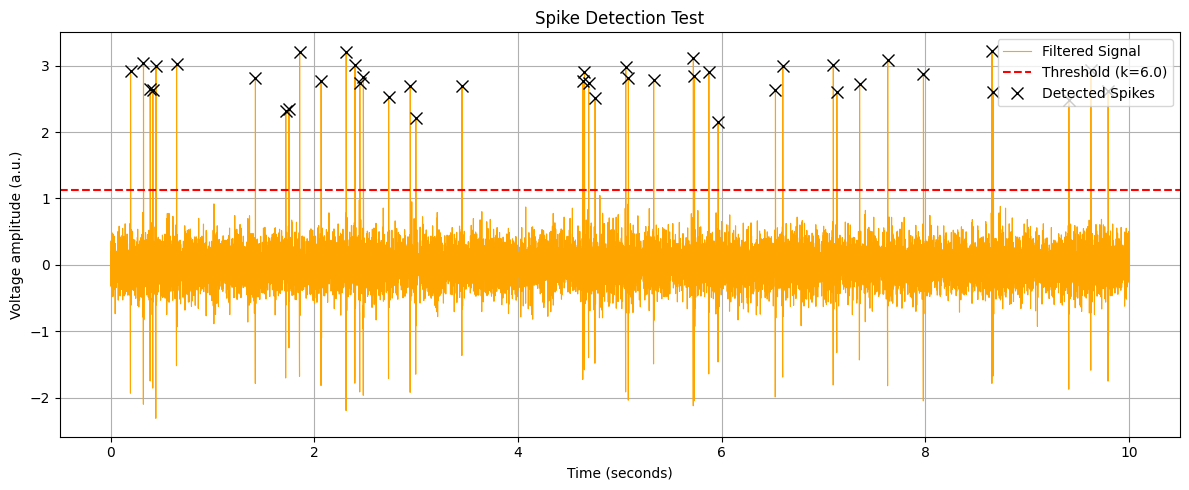


--- Test 2 Results (Refractory Check) ---
Minimum Inter-Spike Interval: 11.0 ms
Success: No refractory period violations detected.

--- Test 3 Results (k-Sensitivity) ---
k = 4 -> Threshold: 0.7475 -> Spikes found: 74
k = 5 -> Threshold: 0.9345 -> Spikes found: 45
k = 7 -> Threshold: 1.3086 -> Spikes found: 42


In [56]:
from scipy.signal import find_peaks

# --- Setup ---
signal_median = np.median(filtered_data_standard)
signal_mad = np.median(np.abs(filtered_data_standard - signal_median))
sampling_rate = 1000  # Hz (1 sample = 1 ms)

# TEST 1: Visual Validation & Peak Detection
k_main = 6.0
threshold = signal_median + k_main * signal_mad
min_distance = 2  # 2 ms refractory period

peaks, _ = find_peaks(filtered_data_standard, height=threshold, distance=min_distance)

print(f"--- Test 1 Results ---")
print(f"Threshold (k={k_main}): {threshold:.4f}")
print(f"Total Spikes Detected: {len(peaks)}")

# Plotting
plt.figure(figsize=(12, 5))
plt.plot(time, filtered_data_standard, color='orange', linewidth=0.8, label='Filtered Signal')
plt.axhline(y=threshold, color='red', linestyle='--', label=f'Threshold (k={k_main})')
plt.plot(time[peaks], filtered_data_standard[peaks], "x", color='black', markersize=8, label='Detected Spikes')
plt.title('Spike Detection Test')
plt.xlabel('Time (seconds)')
plt.ylabel('Voltage amplitude (a.u.)')
plt.legend(loc='upper right')
plt.grid(True)
plt.tight_layout()
plt.show()

# TEST 2: Refractory Period Check
# Calculate time differences between consecutive spikes in milliseconds
spike_times = time[peaks] * 1000  # convert to ms
isis = np.diff(spike_times)

print(f"\n--- Test 2 Results (Refractory Check) ---")
if len(isis) > 0:
    min_isi = np.min(isis)
    print(f"Minimum Inter-Spike Interval: {min_isi:.1f} ms")
    if min_isi >= min_distance:
        print("Success: No refractory period violations detected.")
    else:
        print("Warning: Some spikes occurred closer than the minimum distance.")
else:
    print("Not enough spikes detected to calculate ISI.")

# TEST 3: Parameter Sensitivity Check
print(f"\n--- Test 3 Results (k-Sensitivity) ---")
test_k_values = [4, 5, 7]

for k_val in test_k_values:
    test_thresh = signal_median + k_val * signal_mad
    test_peaks, _ = find_peaks(filtered_data_standard, height=test_thresh, distance=min_distance)
    print(f"k = {k_val} -> Threshold: {test_thresh:.4f} -> Spikes found: {len(test_peaks)}")

## Detection Specification

The spike detection method consists of four main steps:

1. High-Pass Filtering: Apply a Butterworth high-pass filter to remove slow baseline drift and keep high-frequency neural signals.

2.  Threshold Calculation: Calculate the noise baseline using the median and Median Absolute Deviation (MAD) of the filtered signal. The voltage threshold is set as $\text{Median} + k \times \text{MAD}$ (with $k = 5.0$) to stay safely above the noise floor.

3. Peak Detection: Use SciPy's peak-finding function to identify local maxima that cross the threshold.

4. Refractory Period: Enforce a minimum distance (min_distance = 2 samples, equal to $2\text{ ms}$) between peaks to match the biological refractory period of nerve cells and prevent counting a single spike multiple times.

5. Test

> a. Visual Validation: Plot the filtered signal, the threshold line, and the marked spikes together to check that the algorithm flags real waveforms while ignoring background noise.
>
> b. Parameter Sensitivity: Test small changes in $k$ (such as $4.5$ and $5.5$) to check if the total spike count stays stable. A reliable method should not produce major changes in counts from tiny parameter tweaks.
>
> c. Refractory Check: Calculate the time gaps between detected spikes to verify that no gaps are shorter than the $2\text{ ms}$ biological limit.

